# I 1. Historical Introduction

Apostol, *Calculus*, Vol. 1 (2nd ed.), Introduction, Part 1: Sections I 1.1–I 1.6, pp. 1–10.

*Last updated: 24 October 2026*

## Scope

This notebook follows the six sections of the Historical Introduction and turns its main ideas into short
computations and figures. Sections I 1.5 and I 1.6 are only summarised; they contain nothing to compute.

| Section | Topic | Page | In this notebook |
|---|---|---|---|
| I 1.1 | The two basic concepts of calculus | 1 | Figure 1 |
| I 1.2 | Historical background | 2 | Figure 2 |
| I 1.3 | The method of exhaustion for the area of a parabolic segment | 3 | Figure 3, exact check of (1.3)–(1.5) |
| I 1.4 | Exercises | 8 | Exercises 1–3, Figures 4–6 |
| I 1.5 | A critical analysis of Archimedes' method | 8 | summary |
| I 1.6 | The approach to calculus used in this book | 10 | summary |

Each figure is drawn once with fixed values and saved in `figures/`; these are the images shown on GitHub and in the
HTML file. The sliders under a figure redraw it for other values when the notebook is run in Jupyter.

In [1]:
import sys
from fractions import Fraction
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from ipywidgets import FloatSlider, IntSlider, interact

ROOT = next(p for p in Path.cwd().resolve().parents if (p / "apostol").is_dir())
sys.path.insert(0, str(ROOT))

from apostol.style import (BAND, BLUE, INK, MUTED, auto_axis, end_label, fit_log_axis, save_figure,
                           source_note, use_style, value_axis)
from apostol.sums import (inscribed_semicircle_area, power_sum, rectangle_sums, sum_of_cubes,
                          sum_of_squares)

use_style()


def show_figure(name, draw, heading):
    # Save the figure in figures/ (checked for the axis rule and for overlapping text) and show the saved file.
    display(Image(filename=str(save_figure(name, draw, heading)), width=620))

## I 1.1 The two basic concepts of calculus

A useful way to motivate calculus is to start from two closely related geometric questions. First, given a curve
$y=f(x)$ above the $x$-axis and an interval $[a,b]$, we want to assign one number to the region between the curve, the
axis and the vertical lines $x=a$ and $x=b$: its area. This leads to the integral. Second, given a point $x=c$ on the
same curve, we want to assign one number to the steepness of the tangent line there: its slope. This leads to the
derivative.

In Figure 1 the curve is $f(x) = 1.6 + 0.9\sin x$. The area is computed numerically (trapezoids on 2,000 subintervals)
and the slope by the central difference $\bigl(f(c+h)-f(c-h)\bigr)/2h$; both are compared with the exact values
$\int_a^b f = 1.6(b-a) + 0.9(\cos a - \cos b)$ and $f'(c) = 0.9\cos c$.

area:  numeric 7.622119   exact 7.622119
slope: numeric 0.547516   exact 0.547516


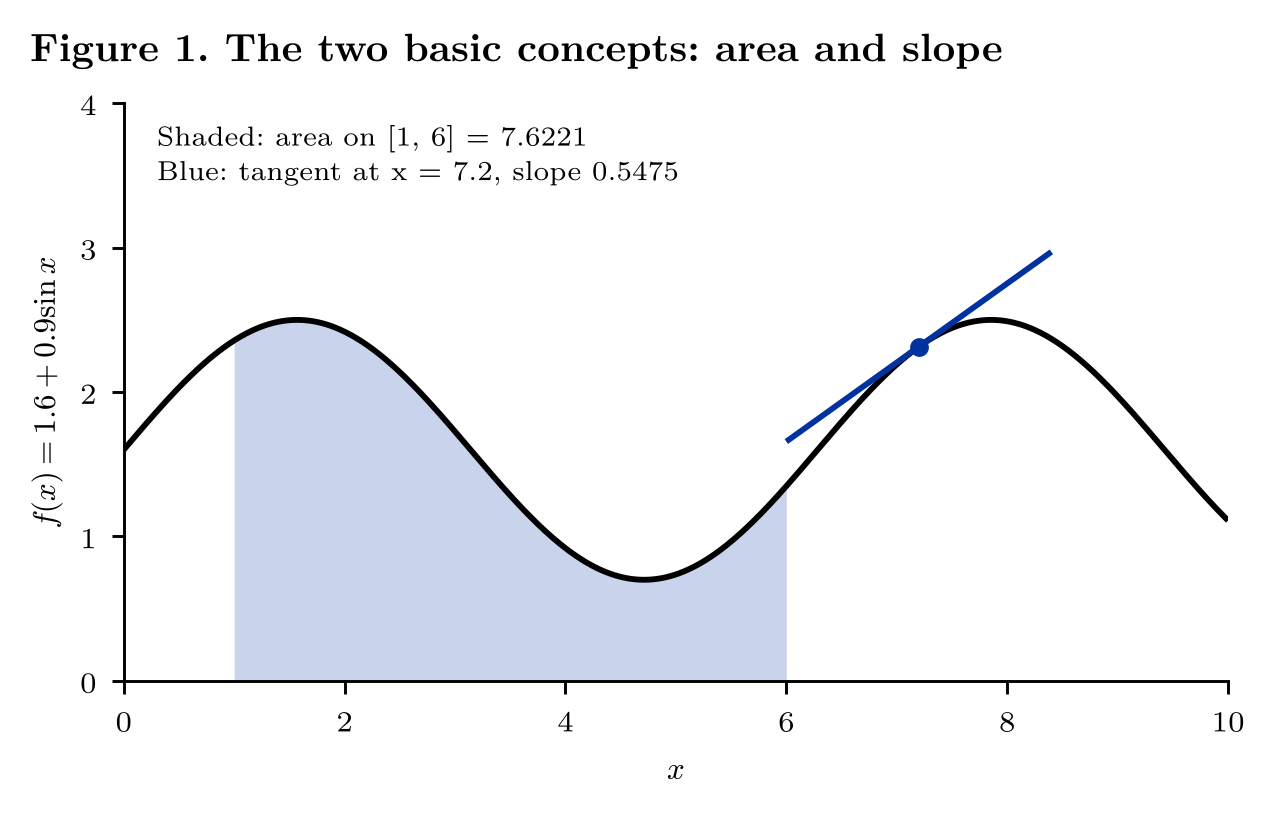

In [2]:
def f(x):
    return 1.6 + 0.9 * np.sin(x)


def area_numeric(a, b, n=2000):
    x = np.linspace(a, b, n + 1)
    y = f(x)
    return float(np.sum((y[:-1] + y[1:]) / 2 * np.diff(x)))


def slope_numeric(c, h=1e-5):
    return (f(c + h) - f(c - h)) / (2 * h)


def draw_two_concepts(a=1.0, b=6.0, c=7.2):
    a, b = sorted((a, b))
    x = np.linspace(0, 10, 1001)
    xs = np.linspace(a, b, 501)
    m = slope_numeric(c)
    t = np.array([max(c - 1.2, 0), min(c + 1.2, 10)])

    fig, ax = plt.subplots(figsize=(4.75, 2.5))
    ax.fill_between(xs, 0, f(xs), color=BAND, lw=0)
    ax.plot(x, f(x), color=INK, label="curve")
    ax.plot(t, f(c) + m * (t - c), color=BLUE, label="tangent")
    ax.plot([c], [f(c)], "o", color=BLUE, ms=3.5)
    value_axis(ax, "x", 0, 10, 2)
    value_axis(ax, "y", 0, 4, 1)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$f(x) = 1.6 + 0.9\\sin x$")
    source_note(ax, f"Shaded: area on [{a:g}, {b:g}] = {area_numeric(a, b):.4f}\n"
                    f"Blue: tangent at x = {c:g}, slope {m:.4f}", y=0.97, va="top")
    return fig


a, b, c = 1.0, 6.0, 7.2
print(f"area:  numeric {area_numeric(a, b):.6f}   exact {1.6 * (b - a) + 0.9 * (np.cos(a) - np.cos(b)):.6f}")
print(f"slope: numeric {slope_numeric(c):.6f}   exact {0.9 * np.cos(c):.6f}")
show_figure("fig1_two_concepts", draw_two_concepts, "Figure 1. The two basic concepts: area and slope")

In [3]:
@interact(a=FloatSlider(value=1.0, min=0, max=10, step=0.1), b=FloatSlider(value=6.0, min=0, max=10, step=0.1),
          c=FloatSlider(value=7.2, min=0, max=10, step=0.1))
def explore_two_concepts(a, b, c):
    draw_two_concepts(a, b, c)
    plt.show()

interactive(children=(FloatSlider(value=1.0, description='a', max=10.0), FloatSlider(value=6.0, description='b…

## I 1.2 Historical background

The integral goes back to the Greek method of exhaustion: a region is filled with polygons whose areas are known, and
the polygons are refined until they "exhaust" the region. Archimedes used it to find exact areas, among them the area
of the circle and of the parabolic segment. Without a convenient algebraic notation the method could not be carried
much further. This changed from the sixteenth century on, with Hindu–Arabic numerals, the symbols $+$ and $-$,
decimal notation and the algebra of Tartaglia, Cardano and Ferrari. In the seventeenth century Cavalieri, Torricelli,
Roberval, Fermat, Pascal and Wallis obtained many partial results; Newton and Leibniz gave the subject its decisive
form, and in the nineteenth century Cauchy and Riemann put it on a rigorous footing.

Figure 2 applies the idea to a half disc of radius 1, whose area is $\pi/2$. Under the polygon inscribed with $n$ equal
steps along the diameter lie $n$ trapezoids; their total area $A_n$ approaches $\pi/2$ from below as $n$ grows.

n =    10   A_n = 1.51852441   pi/2 - A_n = 5.23e-02
n =   100   A_n = 1.56913426   pi/2 - A_n = 1.66e-03
n =  1000   A_n = 1.57074374   pi/2 - A_n = 5.26e-05


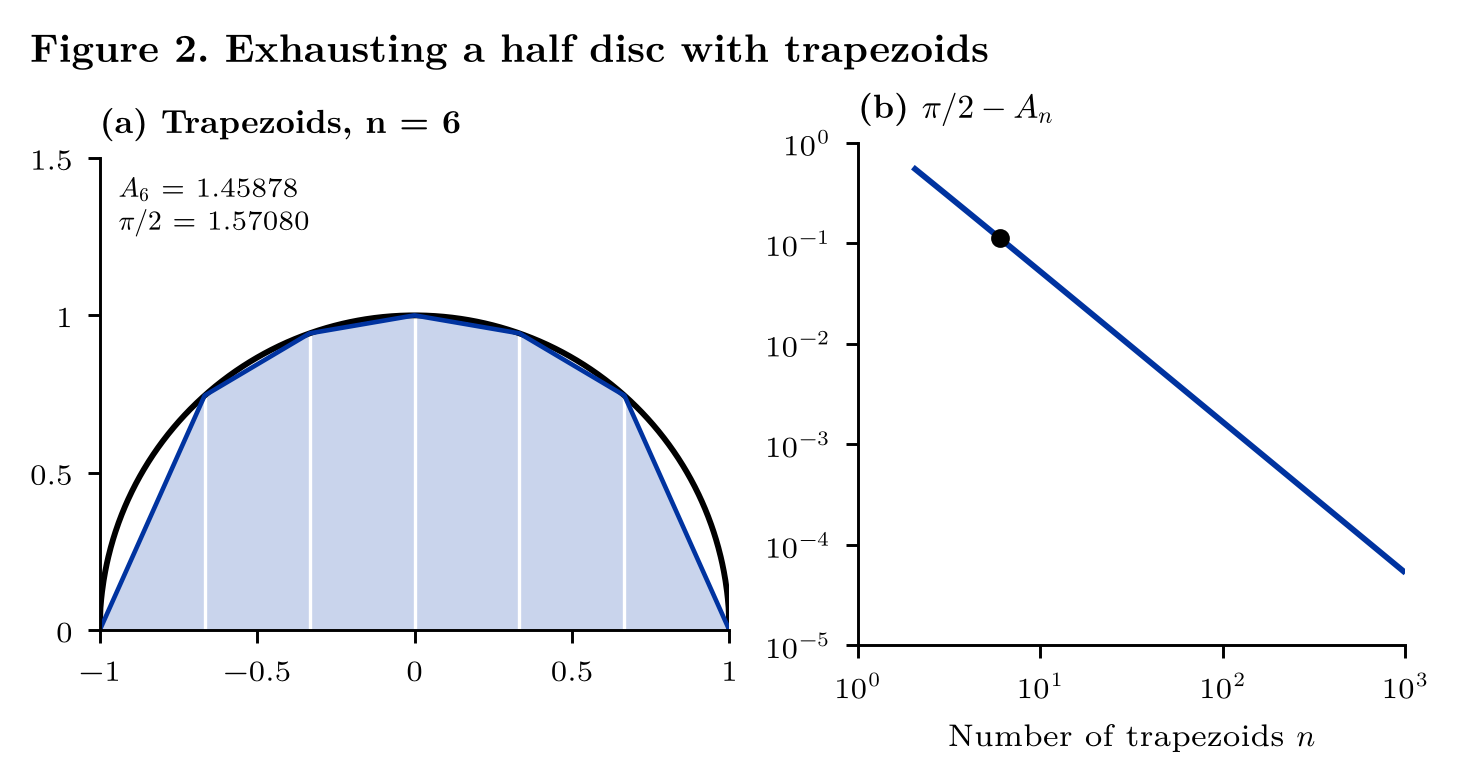

In [4]:
N_ALL = np.unique(np.round(np.logspace(np.log10(2), 3, 60)).astype(int))
GAP_ALL = np.array([np.pi / 2 - inscribed_semicircle_area(n) for n in N_ALL])


def draw_exhaustion(n=6):
    x = np.linspace(-1, 1, n + 1)
    y = np.sqrt(np.clip(1 - x ** 2, 0, None))
    xf = np.linspace(-1, 1, 801)
    a_n = inscribed_semicircle_area(n)

    fig, (ax, bx) = plt.subplots(1, 2, figsize=(4.75, 2.3), constrained_layout=True,
                                 gridspec_kw={"width_ratios": [1.15, 1]})
    ax.fill_between(x, 0, y, color=BAND, lw=0)
    ax.vlines(x[1:-1], 0, y[1:-1], color="white", lw=0.8)
    ax.plot(xf, np.sqrt(1 - xf ** 2), color=INK, label="half circle")
    ax.plot(x, y, color=BLUE, lw=1.1, label="polygon")
    ax.set_aspect("equal")
    value_axis(ax, "x", -1, 1, 0.5)
    value_axis(ax, "y", 0, 1.5, 0.5)
    ax.set_title(f"(a) Trapezoids, n = {n}")
    source_note(ax, f"$A_{{{n}}}$ = {a_n:.5f}\n$\\pi/2$ = {np.pi / 2:.5f}", y=0.97, va="top")

    bx.plot(N_ALL, GAP_ALL, color=BLUE, label="gap")
    bx.plot([n], [np.pi / 2 - a_n], "o", color=INK, ms=3.5)
    fit_log_axis(bx, "x", N_ALL)
    fit_log_axis(bx, "y", GAP_ALL)
    bx.set_xlabel("Number of trapezoids $n$")
    bx.set_title("(b) $\\pi/2 - A_n$")
    return fig


for n in (10, 100, 1000):
    a_n = inscribed_semicircle_area(n)
    print(f"n = {n:5d}   A_n = {a_n:.8f}   pi/2 - A_n = {np.pi / 2 - a_n:.2e}")
show_figure("fig2_exhaustion", draw_exhaustion, "Figure 2. Exhausting a half disc with trapezoids")

In [5]:
@interact(n=IntSlider(value=6, min=2, max=60))
def explore_exhaustion(n):
    draw_exhaustion(n)
    plt.show()

interactive(children=(IntSlider(value=6, description='n', max=60, min=2), Output()), _dom_classes=('widget-int…

## I 1.3 The method of exhaustion for the area of a parabolic segment

The region is bounded by $y = x^2$, the $x$-axis and the line $x = b$. Divide $[0,b]$ into $n$ equal parts of length
$b/n$, with division points $x_k = kb/n$, $k = 0, 1, \dots, n$. Over the $k$-th part, the rectangle whose height is the
value of $x^2$ at the right end lies above the curve; its area is $(b/n)(kb/n)^2 = (b^3/n^3)\,k^2$. Adding these
outer rectangles, and the inner ones whose height is the value at the left end, gives

$$
S_n = \frac{b^3}{n^3}\left(1^2 + 2^2 + \cdots + n^2\right), \tag{1.1}
$$

$$
s_n = \frac{b^3}{n^3}\left(1^2 + 2^2 + \cdots + (n-1)^2\right). \tag{1.2}
$$

The sum of squares has a closed form,

$$
1^2 + 2^2 + \cdots + n^2 = \frac{n^3}{3} + \frac{n^2}{2} + \frac{n}{6}. \tag{1.3}
$$

To see it, add the identities $(k+1)^3 - k^3 = 3k^2 + 3k + 1$ for $k = 1, \dots, n-1$. The left sides telescope to
$n^3 - 1$, and $1 + 2 + \cdots + (n-1) = n(n-1)/2$, so

$$
1^2 + 2^2 + \cdots + (n-1)^2 = \frac{n^3}{3} - \frac{n^2}{2} + \frac{n}{6}; \tag{1.4}
$$

adding $n^2$ gives (1.3). The argument needs only the inequalities

$$
1^2 + 2^2 + \cdots + (n-1)^2 < \frac{n^3}{3} < 1^2 + 2^2 + \cdots + n^2, \tag{1.5}
$$

which follow from (1.3) and (1.4) for every $n \ge 1$. Multiplied by $b^3/n^3$ they read $s_n < b^3/3 < S_n$. A number $A$
with $s_n \le A \le S_n$ for every $n$ therefore satisfies $|A - b^3/3| \le S_n - s_n = b^3/n$ for every $n$, which is
possible only if $A = b^3/3$: the area of the parabolic segment is $b^3/3$.

The next cell checks (1.3), (1.4) and (1.5) in exact integer arithmetic for $n = 1, \dots, 10{,}000$, and prints $s_n$
and $S_n$ for $b = 1$.

In [6]:
N = 10_000
ok_13 = all(6 * power_sum(n, 2) == 2 * n**3 + 3 * n**2 + n for n in range(1, 301))   # brute force for small n
ok_13 &= all(6 * sum_of_squares(n) == 2 * n**3 + 3 * n**2 + n for n in range(1, N + 1))
ok_14 = all(6 * sum_of_squares(n - 1) == 2 * n**3 - 3 * n**2 + n for n in range(1, N + 1))
ok_15 = all(3 * sum_of_squares(n - 1) < n**3 < 3 * sum_of_squares(n) for n in range(1, N + 1))
print(f"(1.3) holds for n = 1..{N:,}: {ok_13}")
print(f"(1.4) holds for n = 1..{N:,}: {ok_14}")
print(f"(1.5) holds for n = 1..{N:,}: {ok_15}")
print()
print("     n          s_n          S_n     S_n - s_n")
for n in (10, 100, 1000, 10_000):
    s_n = Fraction(sum_of_squares(n - 1), n**3)
    S_n = Fraction(sum_of_squares(n), n**3)
    print(f"{n:6d}  {float(s_n):.9f}  {float(S_n):.9f}  {float(S_n - s_n):.1e}")
print(f"  b^3/3 = {1 / 3:.9f}")

(1.3) holds for n = 1..10,000: True
(1.4) holds for n = 1..10,000: True
(1.5) holds for n = 1..10,000: True

     n          s_n          S_n     S_n - s_n
    10  0.285000000  0.385000000  1.0e-01
   100  0.328350000  0.338350000  1.0e-02
  1000  0.332833500  0.333833500  1.0e-03
 10000  0.333283335  0.333383335  1.0e-04
  b^3/3 = 0.333333333


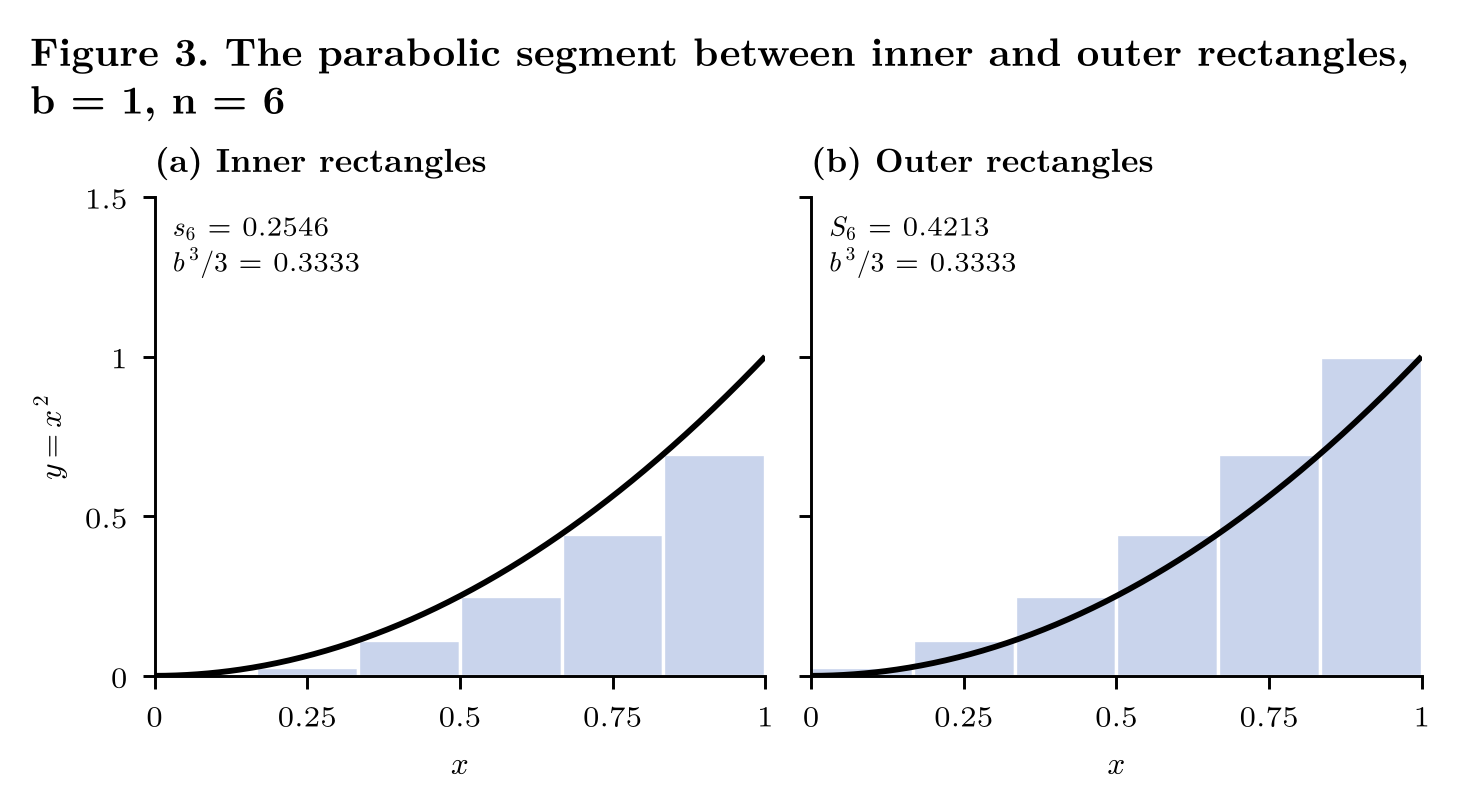

In [7]:
def draw_rectangles(ax, g, b, n, inner=True):
    # Inner (left-end) or outer (right-end) rectangles under an increasing function g on [0, b].
    x = np.linspace(0, b, n + 1)
    heights = g(x[:-1]) if inner else g(x[1:])
    ax.bar(x[:-1], heights, width=b / n, align="edge", color=BAND, edgecolor="white", lw=0.8)
    xf = np.linspace(0, b, 400)
    ax.plot(xf, g(xf), color=INK, label="curve")


def draw_parabolic_segment(n=6, b=1.0):
    s_n, S_n = rectangle_sums(lambda x: x**2, b, n)
    fig, axes = plt.subplots(1, 2, figsize=(4.75, 2.2), constrained_layout=True, sharey=True)
    for ax, inner, label, value in ((axes[0], True, "(a) Inner rectangles", s_n),
                                    (axes[1], False, "(b) Outer rectangles", S_n)):
        draw_rectangles(ax, lambda x: x**2, b, n, inner)
        auto_axis(ax, "x", [0, b], intervals=(2, 4))
        auto_axis(ax, "y", [0, b**2 * 1.45], intervals=(2, 4))
        ax.set_xlabel("$x$")
        ax.set_title(label)
        sym = "s" if inner else "S"
        source_note(ax, f"${sym}_{{{n}}}$ = {value:.4f}\n$b^3/3$ = {b**3 / 3:.4f}", y=0.97, va="top")
    axes[0].set_ylabel("$y = x^2$")
    return fig


show_figure("fig3_parabolic_segment", draw_parabolic_segment,
            "Figure 3. The parabolic segment between inner and outer rectangles, b = 1, n = 6")

In [8]:
@interact(n=IntSlider(value=6, min=1, max=60), b=FloatSlider(value=1.0, min=0.5, max=3.0, step=0.1))
def explore_parabolic_segment(n, b):
    draw_parabolic_segment(n, b)
    plt.show()

interactive(children=(IntSlider(value=6, description='n', max=60, min=1), FloatSlider(value=1.0, description='…

## I 1.4 Exercises (p. 8)

Exercises 1–3 change the function in Figure 3 and repeat the argument. For an increasing function $g$ on $[0,b]$ the
inner sum (left ends) and the outer sum (right ends) enclose the area, and their difference is
$S_n - s_n = \frac{b}{n}\bigl(g(b) - g(0)\bigr)$, which tends to $0$; both sums therefore converge to the area.

### Exercise 1: $y = \alpha x^2 + \beta$

The ordinate $x^2$ of Figure 3 is replaced by $2x^2$, $3x^2$, $\tfrac12 x^2$, $2x^2 + 1$ and, in general, $ax^2 + c$.
With $y = \alpha x^2 + \beta$ ($\alpha > 0$) every rectangle has $\alpha$ times the height of the rectangle for $x^2$,
plus $\beta$, so

$$
s_n = \alpha\,\frac{b^3}{n^3}\bigl(1^2 + \cdots + (n-1)^2\bigr) + \beta b, \qquad
S_n = \alpha\,\frac{b^3}{n^3}\bigl(1^2 + \cdots + n^2\bigr) + \beta b,
$$

and by (1.5) $s_n < \alpha b^3/3 + \beta b < S_n$. The area is

$$
A = \alpha\frac{b^3}{3} + \beta b.
$$

y = 2 x^2 + 0:  s_1000 = 0.665667   A = 0.666667   S_1000 = 0.667667
y = 3 x^2 + 0:  s_1000 = 0.998501   A = 1.000000   S_1000 = 1.001501
y = 0.5 x^2 + 0:  s_1000 = 0.166417   A = 0.166667   S_1000 = 0.166917
y = 2 x^2 + 1:  s_1000 = 1.665667   A = 1.666667   S_1000 = 1.667667


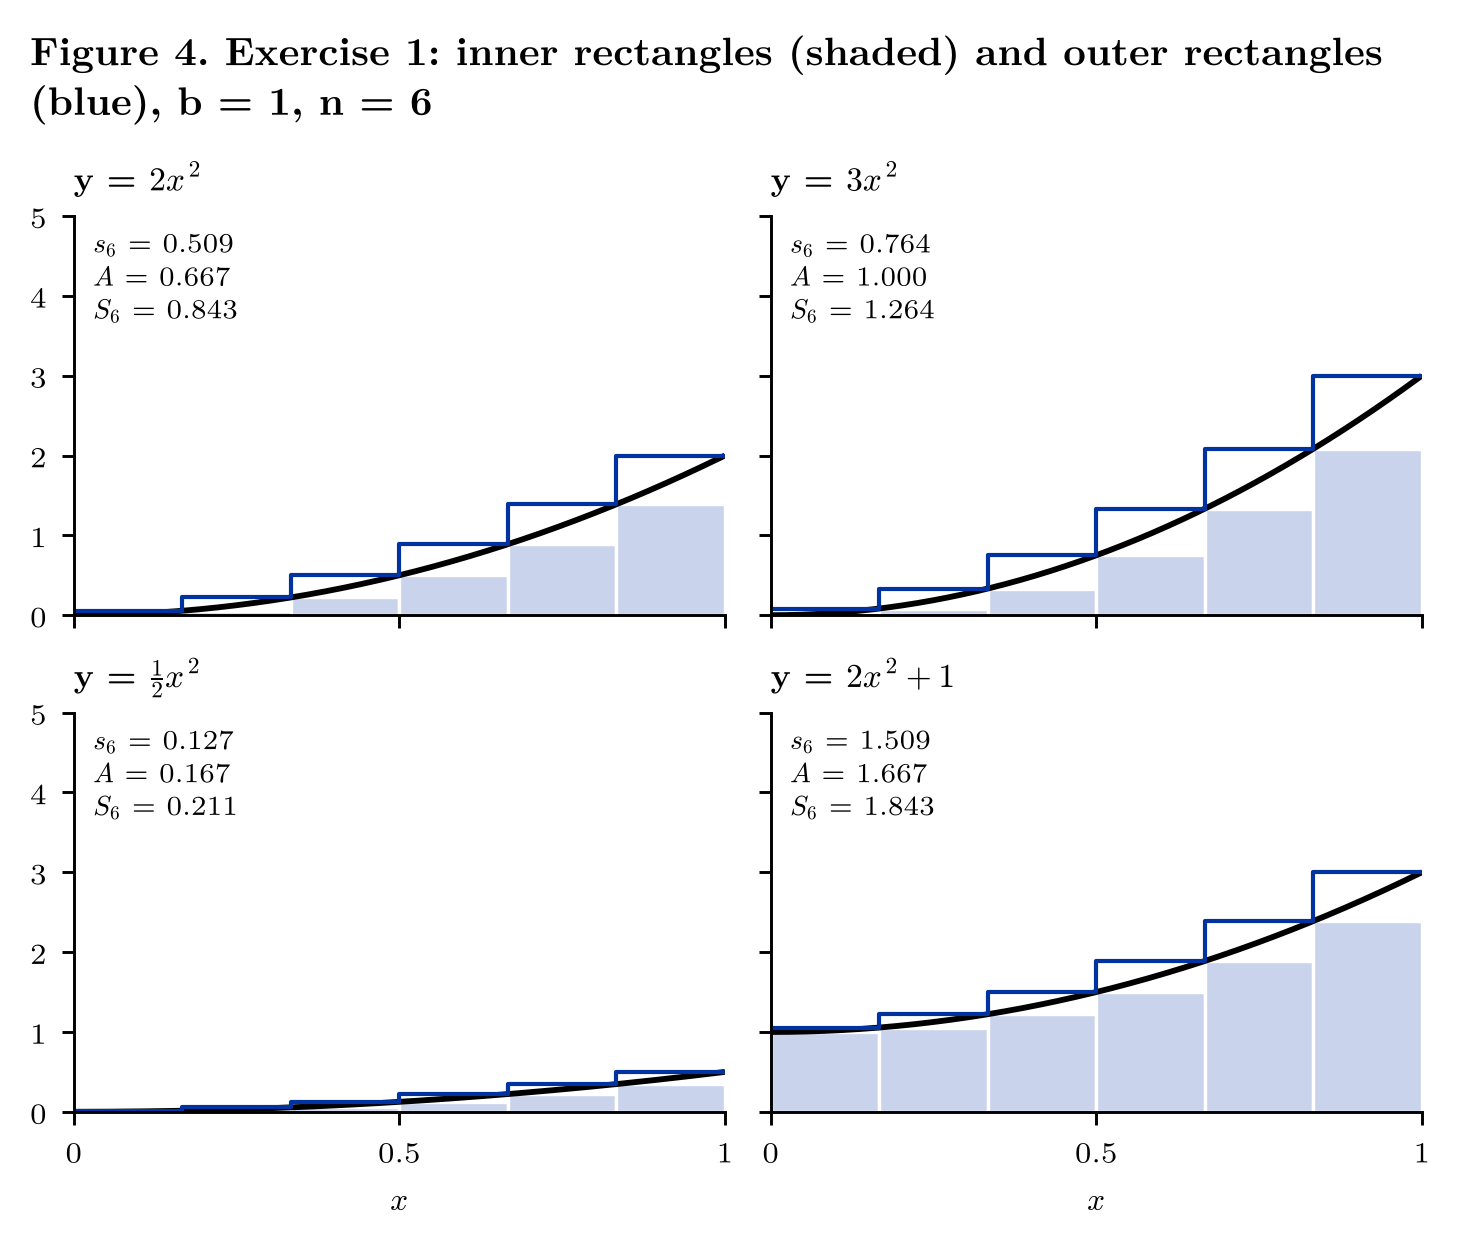

In [9]:
CASES = [(2.0, 0.0, "$2x^2$"), (3.0, 0.0, "$3x^2$"), (0.5, 0.0, "$\\frac{1}{2}x^2$"), (2.0, 1.0, "$2x^2 + 1$")]


def draw_exercise1(n=6, b=1.0):
    fig, axes = plt.subplots(2, 2, figsize=(4.75, 3.6), constrained_layout=True, sharex=True, sharey=True)
    for ax, (alpha, beta, name) in zip(axes.ravel(), CASES):
        g = lambda x, alpha=alpha, beta=beta: alpha * x**2 + beta
        draw_rectangles(ax, g, b, n, inner=True)
        x = np.linspace(0, b, n + 1)
        ax.step(x, np.r_[g(x[1:]), g(x[-1])], where="post", color=BLUE, lw=1.0, label="outer")
        s_n, S_n = rectangle_sums(g, b, n)
        value_axis(ax, "x", 0, 1, 0.5)
        value_axis(ax, "y", 0, 5, 1)
        ax.set_title(f"y = {name}")
        source_note(ax, f"$s_{{{n}}}$ = {s_n:.3f}\n$A$ = {alpha * b**3 / 3 + beta * b:.3f}\n$S_{{{n}}}$ = {S_n:.3f}",
                    y=0.97, va="top")
    for ax in axes[1]:
        ax.set_xlabel("$x$")
    return fig


for alpha, beta, name in CASES:
    s, S = rectangle_sums(lambda x: alpha * x**2 + beta, 1.0, 1000)
    print(f"y = {alpha:g} x^2 + {beta:g}:  s_1000 = {s:.6f}   A = {alpha / 3 + beta:.6f}   S_1000 = {S:.6f}")
show_figure("fig4_exercise1", draw_exercise1,
            "Figure 4. Exercise 1: inner rectangles (shaded) and outer rectangles (blue), b = 1, n = 6")

In [10]:
@interact(alpha=FloatSlider(value=2.0, min=0.1, max=4.0, step=0.1), beta=FloatSlider(value=1.0, min=0, max=2, step=0.1),
          b=FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1), n=IntSlider(value=6, min=1, max=60))
def explore_exercise1(alpha, beta, b, n):
    g = lambda x: alpha * x**2 + beta
    s_n, S_n = rectangle_sums(g, b, n)
    fig, ax = plt.subplots(figsize=(4.75, 2.5))
    draw_rectangles(ax, g, b, n, inner=True)
    x = np.linspace(0, b, n + 1)
    ax.step(x, np.r_[g(x[1:]), g(x[-1])], where="post", color=BLUE, lw=1.0)
    auto_axis(ax, "x", [0, b], intervals=(2, 5))
    auto_axis(ax, "y", [0, 1.5 * g(b)])
    source_note(ax, f"$s_n$ = {s_n:.4f},  $A$ = {alpha * b**3 / 3 + beta * b:.4f},  $S_n$ = {S_n:.4f}",
                y=0.97, va="top")
    plt.show()

interactive(children=(FloatSlider(value=2.0, description='alpha', max=4.0, min=0.1), FloatSlider(value=1.0, de…

### Exercise 2: $y = x^3$

Now the rectangle sums are $\frac{b^4}{n^4}$ times sums of cubes. Adding $(k+1)^4 - k^4 = 4k^3 + 6k^2 + 4k + 1$ for
$k = 1, \dots, n$ gives the closed form

$$
1^3 + 2^3 + \cdots + n^3 = \left(\frac{n(n+1)}{2}\right)^2 = \frac{n^4}{4} + \frac{n^3}{2} + \frac{n^2}{4},
$$

hence $1^3 + \cdots + (n-1)^3 < n^4/4 < 1^3 + \cdots + n^3$, so that

$$
s_n = \frac{b^4}{n^4}\bigl(1^3 + \cdots + (n-1)^3\bigr) < \frac{b^4}{4} <
S_n = \frac{b^4}{n^4}\bigl(1^3 + \cdots + n^3\bigr),
$$

and the area under $y = x^3$ on $[0,b]$ is $b^4/4$.

closed form of 1^3 + ... + n^3 holds for n = 1..10,000: True
1^3 + ... + (n-1)^3 < n^4/4 < 1^3 + ... + n^3 for n = 1..10,000: True


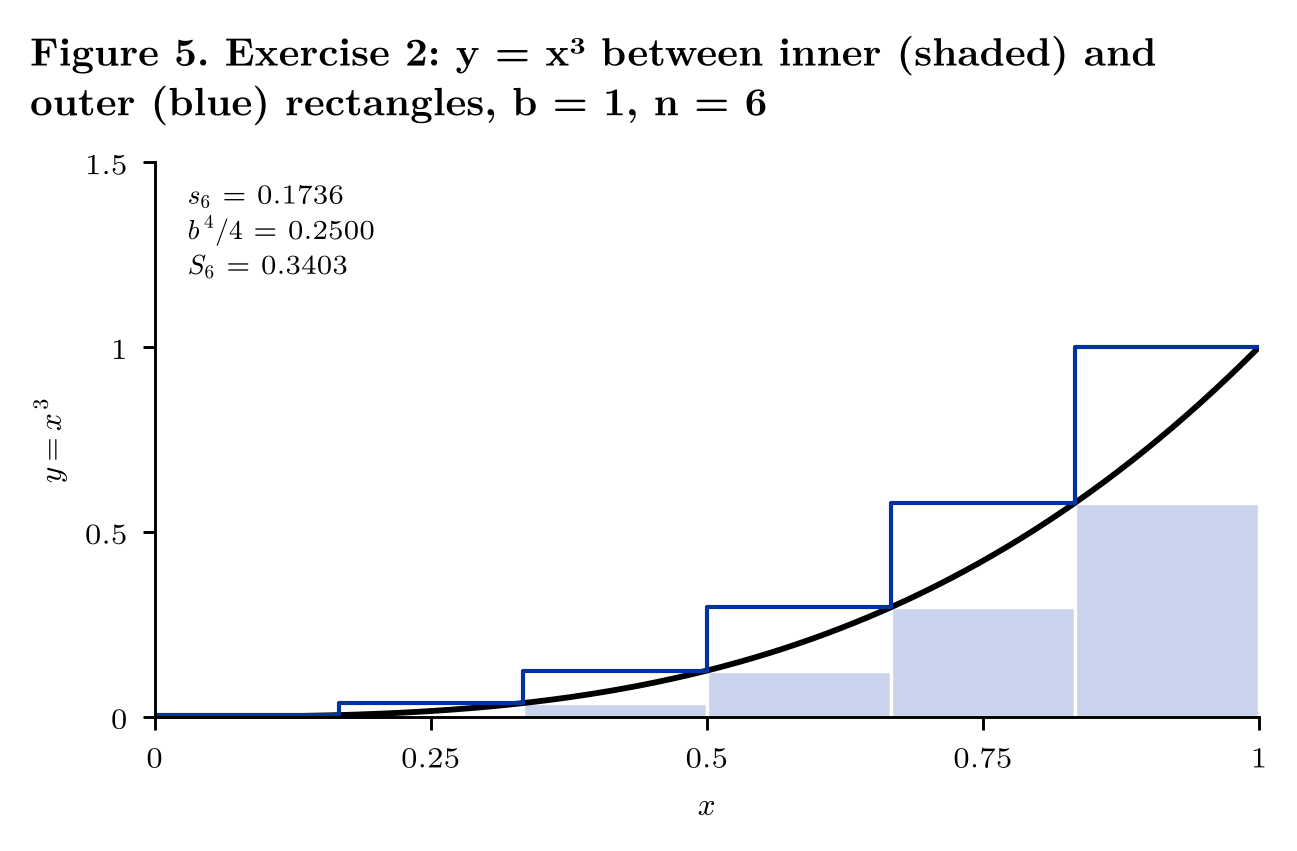

In [11]:
N = 10_000
ok_cubes = all(power_sum(n, 3) == sum_of_cubes(n) for n in range(1, 301))
ok_cubes &= all(4 * sum_of_cubes(n) == n**4 + 2 * n**3 + n**2 for n in range(1, N + 1))
ok_ineq = all(4 * sum_of_cubes(n - 1) < n**4 < 4 * sum_of_cubes(n) for n in range(1, N + 1))
print(f"closed form of 1^3 + ... + n^3 holds for n = 1..{N:,}: {ok_cubes}")
print(f"1^3 + ... + (n-1)^3 < n^4/4 < 1^3 + ... + n^3 for n = 1..{N:,}: {ok_ineq}")


def draw_exercise2(n=6, b=1.0):
    g = lambda x: x**3
    s_n, S_n = rectangle_sums(g, b, n)
    fig, ax = plt.subplots(figsize=(4.75, 2.4))
    draw_rectangles(ax, g, b, n, inner=True)
    x = np.linspace(0, b, n + 1)
    ax.step(x, np.r_[g(x[1:]), g(x[-1])], where="post", color=BLUE, lw=1.0, label="outer")
    auto_axis(ax, "x", [0, b], intervals=(2, 5))
    auto_axis(ax, "y", [0, 1.5 * b**3], intervals=(2, 4))
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y = x^3$")
    source_note(ax, f"$s_{{{n}}}$ = {s_n:.4f}\n$b^4/4$ = {b**4 / 4:.4f}\n$S_{{{n}}}$ = {S_n:.4f}", y=0.97, va="top")
    return fig


show_figure("fig5_exercise2", draw_exercise2,
            "Figure 5. Exercise 2: y = x³ between inner (shaded) and outer (blue) rectangles, b = 1, n = 6")

In [12]:
@interact(n=IntSlider(value=6, min=1, max=60), b=FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1))
def explore_exercise2(n, b):
    draw_exercise2(n, b)
    plt.show()

interactive(children=(IntSlider(value=6, description='n', max=60, min=1), FloatSlider(value=1.0, description='…

### Exercise 3: $y = x^k$

Exercise 3 states the inequality

$$
1^k + 2^k + \cdots + (n-1)^k < \frac{n^{k+1}}{k+1} < 1^k + 2^k + \cdots + n^k \qquad (n \ge 1,\ k \ge 1)
$$

and asks for the area under $y = x^k$ on $[0,b]$. With the same partition the rectangle sums are $b^{k+1}/n^{k+1}$ times
these power sums, so $s_n < b^{k+1}/(k+1) < S_n$ and the area is $b^{k+1}/(k+1)$.

The next cell checks the inequality in exact arithmetic for $k = 1, \dots, 8$ and $n = 1, \dots, 500$. Figure 6 shows
how fast the inner sum approaches the area. Since $1^k + \cdots + (n-1)^k = \frac{n^{k+1}}{k+1} - \frac{n^k}{2} +$ terms of
lower order in $n$, the relative gap $(A - s_n)/A$ behaves like $\frac{k+1}{2n}$: $n$ times the gap approaches
$(k+1)/2$.

inequality of Exercise 3 holds for k = 1..8, n = 1..500: True
k = 1:  n * (A - s_n)/A at n = 1000 is 1.0000
k = 2:  n * (A - s_n)/A at n = 1000 is 1.4995
k = 3:  n * (A - s_n)/A at n = 1000 is 1.9990
k = 4:  n * (A - s_n)/A at n = 1000 is 2.4983


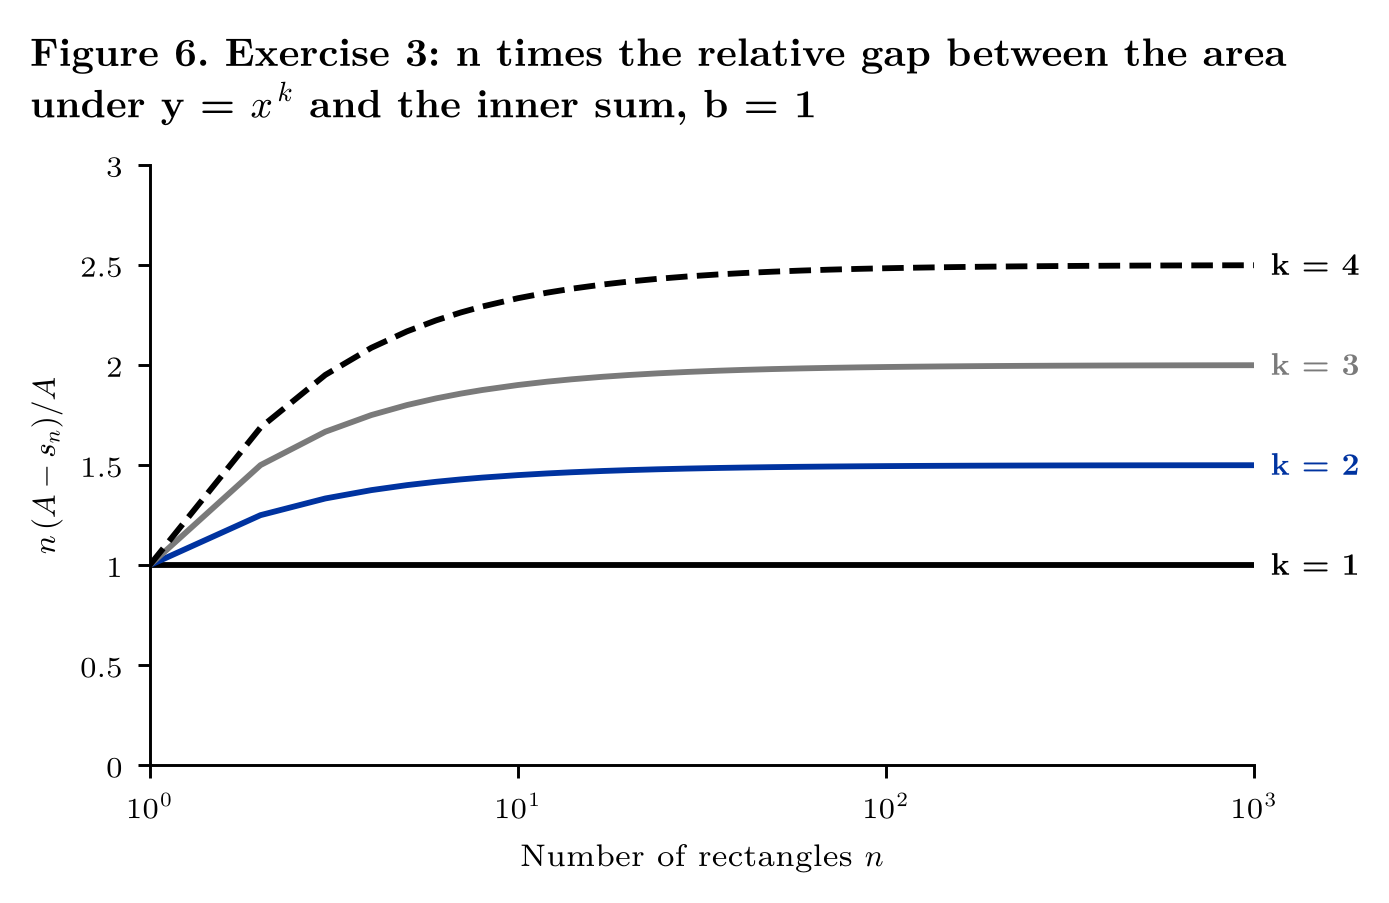

In [13]:
ok = all((k + 1) * power_sum(n - 1, k) < n**(k + 1) < (k + 1) * power_sum(n, k)
         for k in range(1, 9) for n in range(1, 501))
print(f"inequality of Exercise 3 holds for k = 1..8, n = 1..500: {ok}")

N_GAP = np.unique(np.round(np.logspace(0, 3, 40)).astype(int))


def relative_gap(k, n, b=1.0):
    s_n, _ = rectangle_sums(lambda x: x**k, b, n)
    area = b**(k + 1) / (k + 1)
    return (area - s_n) / area


def draw_exercise3():
    fig, ax = plt.subplots(figsize=(4.75, 2.6))
    for k, (color, ls) in zip((1, 2, 3, 4), ((INK, "-"), (BLUE, "-"), (MUTED, "-"), (INK, "--"))):
        g = np.array([n * relative_gap(k, n) for n in N_GAP])
        ax.plot(N_GAP, g, color=color, ls=ls, label=f"k = {k}")
        end_label(ax, N_GAP[-1], g[-1], f"k = {k}", color)
    fit_log_axis(ax, "x", N_GAP)
    value_axis(ax, "y", 0, 3, 0.5)
    ax.set_xlabel("Number of rectangles $n$")
    ax.set_ylabel(r"$n\,(A - s_n)/A$")
    return fig


for k in (1, 2, 3, 4):
    print(f"k = {k}:  n * (A - s_n)/A at n = 1000 is {1000 * relative_gap(k, 1000):.4f}")
show_figure("fig6_exercise3", draw_exercise3,
            "Figure 6. Exercise 3: n times the relative gap between the area under y = $x^k$ and the inner sum, b = 1")

In [14]:
@interact(k=IntSlider(value=3, min=1, max=8), n=IntSlider(value=10, min=1, max=60),
          b=FloatSlider(value=1.0, min=0.5, max=2.0, step=0.1))
def explore_exercise3(k, n, b):
    g = lambda x: x**k
    s_n, S_n = rectangle_sums(g, b, n)
    fig, ax = plt.subplots(figsize=(4.75, 2.5))
    draw_rectangles(ax, g, b, n, inner=True)
    x = np.linspace(0, b, n + 1)
    ax.step(x, np.r_[g(x[1:]), g(x[-1])], where="post", color=BLUE, lw=1.0)
    auto_axis(ax, "x", [0, b], intervals=(2, 5))
    auto_axis(ax, "y", [0, 1.5 * g(b)])
    source_note(ax, f"$s_n$ = {s_n:.4f},  $A$ = {b**(k + 1) / (k + 1):.4f},  $S_n$ = {S_n:.4f}", y=0.97, va="top")
    plt.show()

interactive(children=(IntSlider(value=3, description='k', max=8, min=1), IntSlider(value=10, description='n', …

## I 1.5 A critical analysis of Archimedes' method and I 1.6 The approach to calculus used in this book

These two sections contain no computation and are not implemented here. Section I 1.5 is a discussion of Archimedes'
method, and Section I 1.6 describes the plan of the book. As the table of contents shows, the integral comes first
(Chapter 1, through step functions and upper and lower integrals, which play the role of $s_n$ and $S_n$ above) and
the derivative later (Chapter 4).